<div style="
    background-color: #7BAFD4;
    border-radius: 18px;
    padding: 22px 26px;
    display: flex;
    align-items: center;
    gap: 24px;
    margin-bottom: 18px;
">
    <img src="592_avatar_lr.png" alt="GEOG 592"
        style="width:110px;height:110px;border-radius:22px;">
    <div>
        <div style="
            font-family: Impact, 'Arial Black', Arial, sans-serif;
            font-size: 42px;
            font-weight: 900;
            letter-spacing: 2px;
            line-height: 1;
            color: white;
        ">GEOG 592</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 22px;
            font-weight: 700;
            color: #13294B;
            margin-top: 8px;
        ">GIS Programming</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 16px;
            color: #13294B;
            margin-top: 6px;
        ">Cartography example legend</div>
    </div>
</div>



In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

In [8]:
import os
print(os.getcwd())
print(sorted(f for f in os.listdir() if f.endswith(".zip")))

/Users/scarling/geog592-hailrod/schedule/week09
['cb_2024_us_state_500k.zip']


<Axes: >

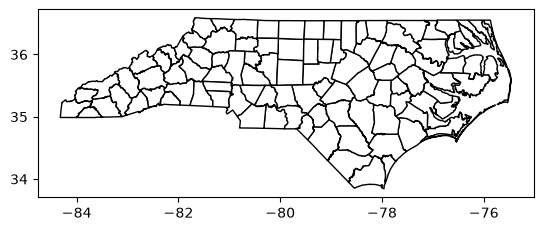

In [10]:


# getting the US census data

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 


## Code for county level data 

counties = gpd.read_file("../../homework/week09/cb_2024_us_county_500k.zip")
nc_counties = counties.loc[counties["STATEFP"] == "37"].copy()
nc_counties.plot(edgecolor="black", facecolor="white")

<Axes: >

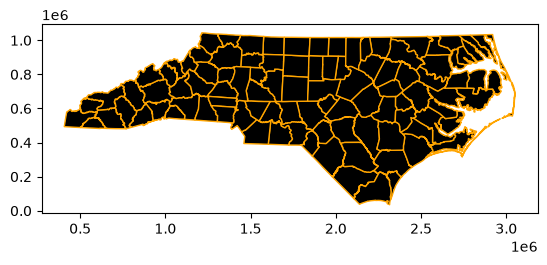

In [14]:
ncc = nc_counties.to_crs(6543).copy() # reproject to NAD83 / North Carolina (ftUS) for better visualization
ncc.plot(edgecolor="orange", facecolor="black")

In [22]:
def ncplot(ax, stroke, fill):
    ncc.plot(ax=ax, edgecolor=stroke, facecolor=fill)

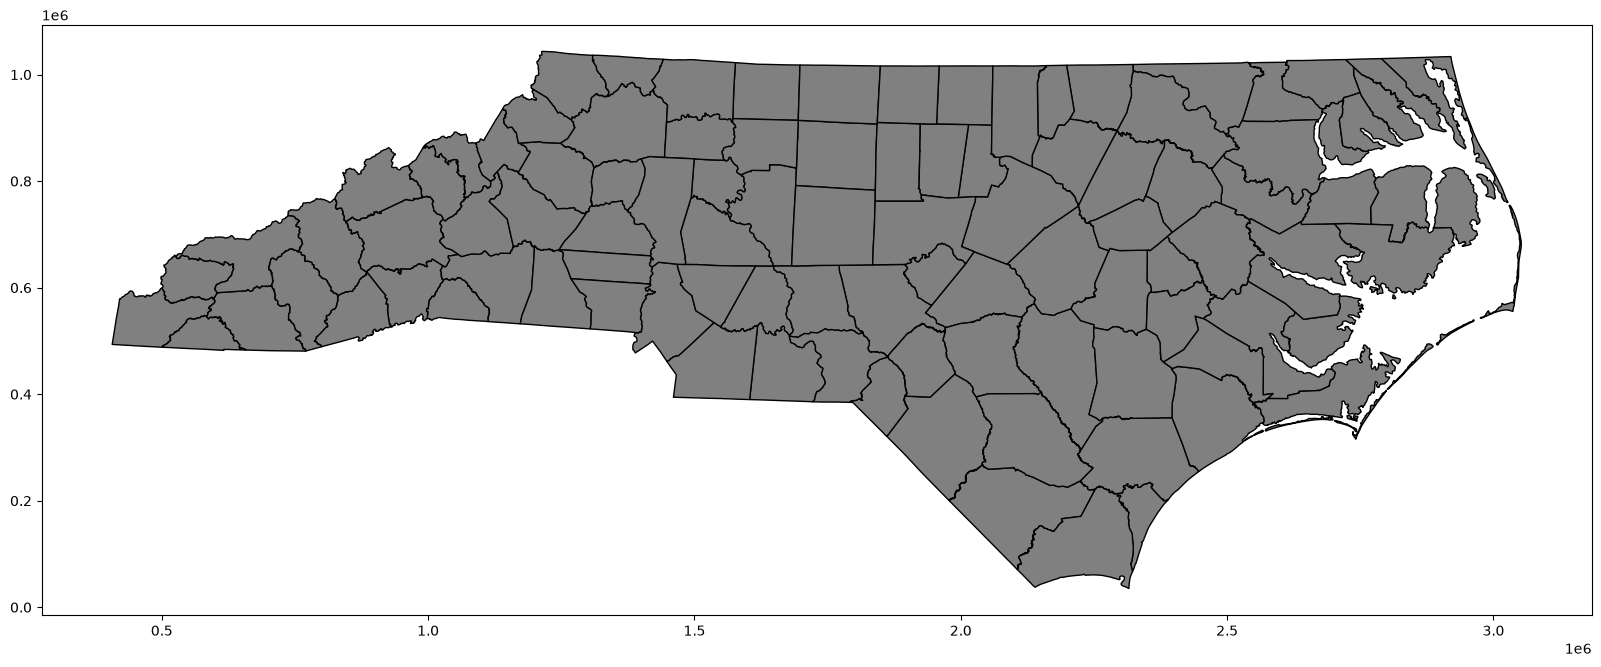

In [25]:
fig, ax = plt.subplots(figsize=(20,10))
ncplot(ax, 'black', 'gray')
plt.show()

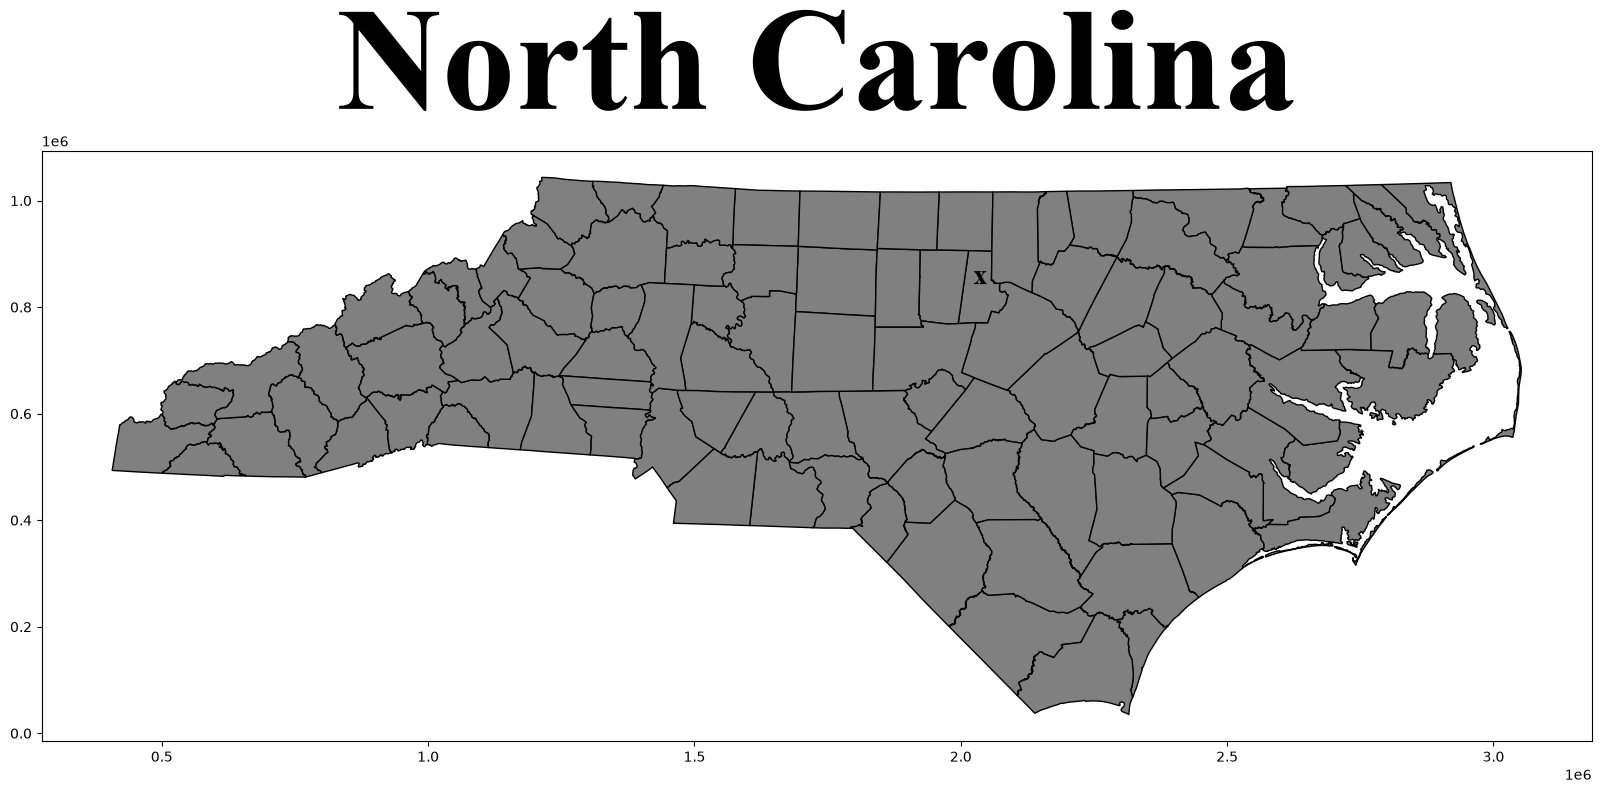

In [55]:
fig, ax = plt.subplots(figsize=(20,10))
ncplot(ax, 'black', 'gray')
ax.set_title("North Carolina", fontsize=105, pad=30, fontweight="bold", fontname="TIMES NEW ROMAN") 
ax.text(
    2036476.502, 831990.2379, "x", ha="center", va="bottom", fontsize=20, fontweight="bold", fontname="Times New Roman"
) 
plt.show()

In [42]:
ncc_copy = ncc.copy()
ncc_copy["geometry"]= ncc_copy.geometry.centroid
ncc_copy["geometry"].head
ncc_copy[ncc_copy["NAME"] == "Durham"].geometry.centroid

1931    POINT (2036476.502 831990.237)
dtype: geometry

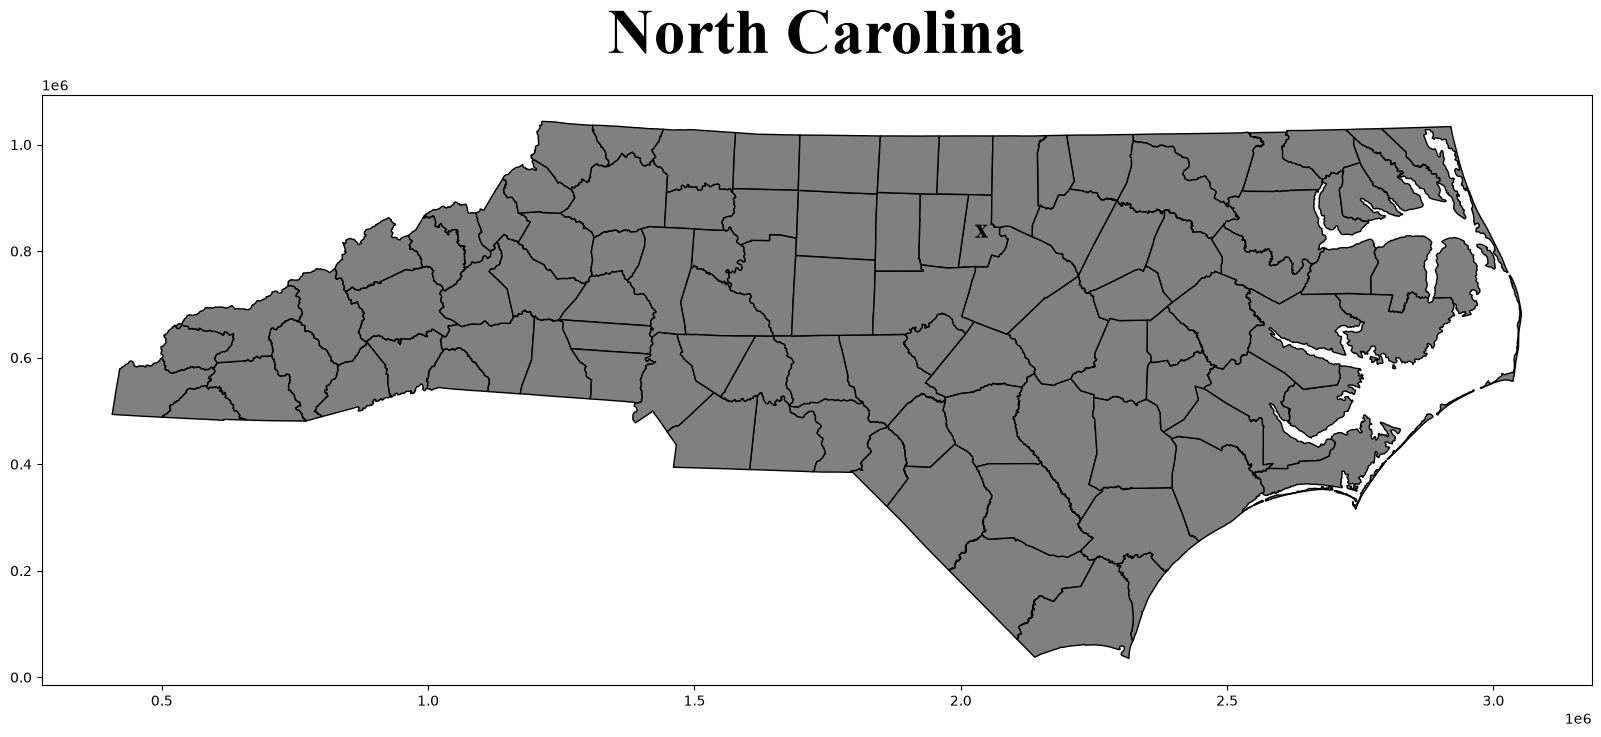

In [50]:
fig, ax = plt.subplots(figsize=(20, 10))
ncplot(ax, 'black', 'gray')
ax.set_title("North Carolina", fontsize=45, pad=30, fontweight="bold", fontname="Times New Roman")

# find a point inside Durham County (in the map's own coordinates)
durham = ncc.loc[ncc["NAME"] == "Durham"].geometry.representative_point().iloc[0]

ax.text(
    durham.x, durham.y, "x", ha="center", va="center",
    fontsize=20, fontweight="bold", fontname="Times New Roman", color="black"
)
plt.show()

In [65]:
for row in ncc_copy.itertuples():
    print(row)

Pandas(Index=90, STATEFP='37', COUNTYFP='047', COUNTYNS='01026339', GEOIDFQ='0500000US37047', GEOID='37047', NAME='Columbus', NAMELSAD='Columbus County', STUSPS='NC', STATE_NAME='North Carolina', LSAD='06', ALAND=2429920494, AWATER=43711694, geometry=<POINT (2104249.345 187867.293)>)
Pandas(Index=91, STATEFP='37', COUNTYFP='039', COUNTYNS='01008545', GEOIDFQ='0500000US37039', GEOID='37039', NAME='Cherokee', NAMELSAD='Cherokee County', STUSPS='NC', STATE_NAME='North Carolina', LSAD='06', ALAND=1179842036, AWATER=28813680, geometry=<POINT (486772.115 542262.558)>)
Pandas(Index=92, STATEFP='37', COUNTYFP='149', COUNTYNS='01008579', GEOIDFQ='0500000US37149', GEOID='37149', NAME='Polk', NAMELSAD='Polk County', STUSPS='NC', STATE_NAME='North Carolina', LSAD='06', ALAND=615606325, AWATER=1964035, geometry=<POINT (1054205.576 571670.468)>)
Pandas(Index=93, STATEFP='37', COUNTYFP='009', COUNTYNS='01008535', GEOIDFQ='0500000US37009', GEOID='37009', NAME='Ashe', NAMELSAD='Ashe County', STUSPS='NC

In [81]:
for name in ncc_copy["NAME"]:
    point = ncc_copy['geometry'][ncc_copy["NAME"] == name]
    print(name)
    print(type(point))
    print(point.geometry.x)
    print(point.geometry.y)

Columbus
<class 'geopandas.geoseries.GeoSeries'>
90    2.104249e+06
dtype: float64
90    187867.292901
dtype: float64
Cherokee
<class 'geopandas.geoseries.GeoSeries'>
91    486772.114791
dtype: float64
91    542262.557899
dtype: float64
Polk
<class 'geopandas.geoseries.GeoSeries'>
92    1.054206e+06
dtype: float64
92    571670.467897
dtype: float64
Ashe
<class 'geopandas.geoseries.GeoSeries'>
93    1.264466e+06
dtype: float64
93    986177.557595
dtype: float64
Dare
<class 'geopandas.geoseries.GeoSeries'>
94    2.949355e+06
dtype: float64
94    754887.688612
dtype: float64
Hertford
<class 'geopandas.geoseries.GeoSeries'>
95    2.594241e+06
dtype: float64
95    955648.762878
dtype: float64
Wilkes
<class 'geopandas.geoseries.GeoSeries'>
217    1.361864e+06
dtype: float64
217    900902.102395
dtype: float64
Rowan
<class 'geopandas.geoseries.GeoSeries'>
218    1.547023e+06
dtype: float64
218    691123.075165
dtype: float64
Henderson
<class 'geopandas.geoseries.GeoSeries'>
219    962362.2681

In [70]:
for row in ncc_copy["NAME"]:
    print(row)

Columbus
Cherokee
Polk
Ashe
Dare
Hertford
Wilkes
Rowan
Henderson
Sampson
Mitchell
Stanly
Anson
Robeson
New Hanover
Pender
Onslow
Clay
Macon
Transylvania
Craven
Pamlico
Tyrrell
Currituck
Northampton
Graham
Harnett
Moore
Martin
Cumberland
Davie
Halifax
Caldwell
Nash
Bertie
Hoke
Brunswick
Mecklenburg
Person
Haywood
Buncombe
Edgecombe
Camden
Rutherford
Johnston
Greene
Davidson
Montgomery
Yancey
Scotland
Beaufort
Pitt
Jackson
Hyde
Swain
Carteret
Richmond
Jones
Bladen
McDowell
Pasquotank
Burke
Madison
Wake
Guilford
Wayne
Randolph
Stokes
Yadkin
Surry
Cleveland
Alamance
Durham
Catawba
Lincoln
Union
Avery
Gates
Warren
Wilson
Alexander
Watauga
Chowan
Perquimans
Cabarrus
Vance
Rockingham
Alleghany
Lee
Lenoir
Orange
Duplin
Chatham
Granville
Forsyth
Franklin
Iredell
Washington
Gaston
Caswell
